### Прогнозирование стоимости недвижимости
#### Выполняли: Еникеев Тимур Ришатович, Гареев Рустам Ирекович

Цель проекта: исследовать данные о недвижимости в Турции и построить модель регрессии для прогнозирования стоимости объекта.

В работе выполнены загрузка и первичный анализ данных, обработка пропусков и аномальных значений, создание дополнительных признаков, обучение нескольких моделей и проверка итогового Random Forest.

### Источник данных

В работе используется датасет объявлений о недвижимости Турции Zingat.

Основные характеристики набора:
- около 403 тысяч объявлений;
- данные по городам и районам Турции;
- цена объекта указана в турецких лирах;
- целевая переменная — `price`.

В дальнейшем исходные признаки используются для анализа рынка и построения модели.

### Описание основных признаков

**Локация:**
- `city` — город;
- `district` — район;
- `neighborhood` — микрорайон.

**Характеристики объекта:**
- `type` — тип недвижимости;
- `sub_type` — подтип;
- `room_count` — количество комнат;
- `size` — площадь;
- `building_age` — возраст здания;
- `total_floor_count` — количество этажей;
- `floor_no` — этаж.

Часть текстовых признаков далее преобразуется в числовой вид или кодируется перед обучением модели.

### Прогнозирование стоимости недвижимости

Работа посвящена анализу рынка недвижимости Турции и построению модели машинного обучения для оценки стоимости объектов.

Основные этапы:
1. исследование исходного датасета;
2. очистка и подготовка признаков;
3. построение нескольких регрессионных моделей;
4. подбор параметров;
5. сравнение результатов;
6. проверка выбранной модели на тестовых объектах.

В качестве итоговой модели используется Random Forest.

## 1. Импорт библиотек и настройка окружения

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import sys
import re
import joblib
from pathlib import Path
import warnings
from IPython.display import display
from scipy.stats import skew, kurtosis
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", palette="Set2")
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['font.family'] = 'DejaVu Sans'

RANDOM_STATE = 42

# ---------------------------------------------------------------------------
# ПУТИ. Корень проекта и папка с данными (Windows).
# Ноутбук переходит в PROJECT_DIR, поэтому real_estate_features.py, модель (.pkl),
# тестовый CSV и результаты всегда лежат в одном и том же месте.
# ---------------------------------------------------------------------------
PROJECT_DIR = Path(r"C:\Users\Dota3\Downloads\turkey\turkey")
DATA_DIR = PROJECT_DIR / "data"

if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Не найдена папка проекта: {PROJECT_DIR}")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("Рабочая папка :", Path.cwd())
print("Папка с данными:", DATA_DIR, "(есть)" if DATA_DIR.exists() else "(НЕ НАЙДЕНА!)")


Рабочая папка : C:\Users\Dota3\Downloads\turkey\turkey
Папка с данными: C:\Users\Dota3\Downloads\turkey\turkey\data (есть)


In [2]:
%%writefile real_estate_features.py
"""Признаки для модели стоимости недвижимости (Zingat, Турция).

Модуль вынесен из ноутбука, чтобы pickle-файл pipeline можно было загрузить
в приложении (Streamlit/FastAPI): положите этот файл рядом с приложением.
"""
import re

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# --------------------------------------------------------------------------
# Валюты. Цена в датасете указана в валюте объявления (TRY / EUR / USD ...).
# Курсы ПРИБЛИЗИТЕЛЬНЫЕ (средние за период сбора: осень 2018 - весна 2019).
# Неточность курса частично компенсируется тем, что price_currency
# дополнительно подаётся модели как признак.
# --------------------------------------------------------------------------
FX_TO_TRY = {'TRY': 1.0, 'TL': 1.0, 'USD': 5.5, 'EUR': 6.3, 'GBP': 7.0}


def to_try(price, currency, default_currency='TRY'):
    """Переводит цену в турецкие лиры. Неизвестная валюта -> NaN."""
    price = pd.to_numeric(pd.Series(price), errors='coerce')
    cur = pd.Series(currency, index=price.index).fillna(default_currency)
    cur = cur.astype(str).str.strip().str.upper()
    rate = cur.map(FX_TO_TRY)
    return price * rate


# --------------------------------------------------------------------------
# Парсеры текстовых значений
# --------------------------------------------------------------------------
_NUM = re.compile(r'\d+')
_NEG = re.compile(r'-\s*(\d+)')  # этаж ниже нулевой отметки: 'Цокольный этаж -2'
TOP_FLOOR = 9999.0  # маркер "последний/мансардный этаж"


def _nums(s):
    return [int(n) for n in _NUM.findall(s)]


def _is_number(x):
    return isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool)


def parse_building_age(x):
    """'0' -> 0, '6-10 лет' -> 8, '21 и более' -> 21, '20 ve üzeri' -> 20."""
    if pd.isna(x):
        return np.nan
    if _is_number(x):
        return float(x)
    s = str(x).strip().lower()
    n = _nums(s)
    if len(n) >= 2:
        return (n[0] + n[1]) / 2.0
    if len(n) == 1:
        return float(n[0])
    if any(k in s for k in ('нов', 'yeni', 'sıfır', 'строя', 'inşaat')):
        return 0.0
    return np.nan


def parse_total_floors(x):
    """'5' -> 5, '10-20' -> 15 (середина диапазона), '20 и более' -> 20."""
    if pd.isna(x):
        return np.nan
    if _is_number(x):
        return float(x)
    n = _nums(str(x))
    if len(n) >= 2:
        return (n[0] + n[1]) / 2.0
    if len(n) == 1:
        return float(n[0])
    return np.nan


def parse_floor_no(x):
    """Номер этажа. 'Цокольный этаж -2' -> -2, подвал -> -1, цоколь/сад/вход -> 0,
    'Первый этаж' и 'Высокий первый этаж' -> 1, мансарда/крыша/последний этаж ->
    TOP_FLOOR (позже заменяется на total_floor_count)."""
    if pd.isna(x):
        return np.nan
    if _is_number(x):
        return float(x)
    s = str(x).strip().lower()
    if any(k in s for k in ('мансард', 'çatı', 'cati', 'крыш', 'чердак', 'последн')):
        return TOP_FLOOR
    if any(k in s for k in ('подвал', 'bodrum', 'полуподвал')):
        return -1.0
    neg = _NEG.search(s)
    if neg:
        return -float(neg.group(1))
    if any(k in s for k in ('цокол', 'zemin', 'giriş', 'giris', 'входн', 'земл', 'сад', 'bahçe', 'bahce')):
        return 0.0
    if any(k in s for k in ('высок', 'yüksek', 'yuksek', 'первый', 'first', 'birinci')):
        return 1.0
    n = _nums(s)
    return float(n[0]) if n else np.nan


def parse_rooms(x):
    """'3+1' -> 4 (сумма цифр)."""
    if pd.isna(x):
        return np.nan
    n = _nums(str(x))
    return float(sum(n)) if n else np.nan


def parse_bedrooms(x):
    """'3+1' -> 3 (первая цифра)."""
    if pd.isna(x):
        return np.nan
    n = _nums(str(x))
    return float(n[0]) if n else np.nan


def map_unique(series, func):
    """Применяет func только к уникальным значениям (быстро на 400k строк)."""
    uniq = pd.Series(series.dropna().unique())
    mapping = {u: func(u) for u in uniq}
    return series.map(mapping).astype(float)


def _col(X, name):
    return X[name] if name in X.columns else pd.Series(np.nan, index=X.index, dtype=object)


# --------------------------------------------------------------------------
# Главный трансформер: сырые столбцы объявления -> модельные признаки
# --------------------------------------------------------------------------
RAW_FEATURES = ['sub_type', 'start_date', 'listing_type', 'building_age',
                'total_floor_count', 'floor_no', 'room_count', 'size',
                'heating_type', 'price_currency', 'city', 'district',
                'neighborhood']

NUM_COLS = ['size', 'log_size', 'size_missing', 'size_per_room',
            'building_age', 'building_age_missing', 'is_new_building',
            'total_floor_count', 'floor_no', 'floor_ratio',
            'is_top_floor', 'is_ground_floor',
            'rooms_numeric', 'bedrooms', 'date_num', 'month',
            'district_freq', 'neigh_freq']
LOWCARD_COLS = ['listing_type', 'sub_type', 'heating_type',
                'price_currency', 'room_count']
# Географические ключи включают listing_type: уровень цен продажи и аренды
# отличается в ~100 раз, поэтому кодируем их отдельно.
HIGHCARD_COLS = ['city_lt', 'district_lt', 'neigh_lt']


class RealEstateFeatures(BaseEstimator, TransformerMixin):
    """Парсинг + заполнение площади + географические ключи.
    Всё, что считается по данным (медианы, частоты), обучается только в fit()."""

    SIZE_MIN, SIZE_MAX = 10.0, 1000.0
    DATE_ORIGIN = pd.Timestamp('2018-01-01')

    # -- служебное -------------------------------------------------------
    def _prepare(self, X):
        X = pd.DataFrame(X).copy()
        out = pd.DataFrame(index=X.index)

        size = pd.to_numeric(_col(X, 'size'), errors='coerce')
        size = size.where((size >= self.SIZE_MIN) & (size <= self.SIZE_MAX))
        out['size_raw'] = size
        out['rooms_numeric'] = map_unique(_col(X, 'room_count'), parse_rooms)
        out['bedrooms'] = map_unique(_col(X, 'room_count'), parse_bedrooms)

        for c in ['listing_type', 'sub_type', 'heating_type', 'price_currency',
                  'room_count', 'city', 'district', 'neighborhood']:
            out[c] = _col(X, c).astype('object').where(_col(X, c).notna(), 'Unknown').astype(str)

        out['building_age'] = map_unique(_col(X, 'building_age'), parse_building_age)
        out['total_floor_count'] = map_unique(_col(X, 'total_floor_count'), parse_total_floors)
        floor = map_unique(_col(X, 'floor_no'), parse_floor_no)
        is_top = floor == TOP_FLOOR
        floor = floor.where(~is_top, out['total_floor_count'])
        out['floor_no'] = floor
        out['is_top_floor'] = is_top.astype('float32')

        dt = pd.to_datetime(_col(X, 'start_date'), format='%m/%d/%y', errors='coerce')
        if dt.isna().all():
            dt = pd.to_datetime(_col(X, 'start_date'), errors='coerce')
        out['date_num'] = (dt - self.DATE_ORIGIN).dt.days.astype(float)
        out['month'] = dt.dt.month.astype(float)

        out['city_lt'] = out['listing_type'] + '|' + out['city']
        out['district_lt'] = out['city_lt'] + '|' + out['district']
        out['neigh_lt'] = out['district_lt'] + '|' + out['neighborhood']
        out['_district_key'] = out['city'] + '|' + out['district']
        out['_neigh_key'] = out['_district_key'] + '|' + out['neighborhood']
        out['_size_key'] = out['sub_type'] + '|' + out['rooms_numeric'].astype(str)
        return out

    # -- fit / transform -------------------------------------------------
    def fit(self, X, y=None):
        p = self._prepare(X)
        valid = p['size_raw'].notna()
        self.size_med_key_ = p.loc[valid].groupby('_size_key')['size_raw'].median().to_dict()
        self.size_med_rooms_ = p.loc[valid].groupby('rooms_numeric')['size_raw'].median().to_dict()
        self.size_med_global_ = float(p.loc[valid, 'size_raw'].median()) if valid.any() else 100.0
        self.district_cnt_ = p['_district_key'].value_counts().to_dict()
        self.neigh_cnt_ = p['_neigh_key'].value_counts().to_dict()
        self.n_train_ = len(p)
        return self

    def transform(self, X):
        p = self._prepare(X)
        size = p['size_raw']
        miss = size.isna()
        fill = p['_size_key'].map(self.size_med_key_)
        fill = fill.fillna(p['rooms_numeric'].map(self.size_med_rooms_))
        fill = fill.fillna(self.size_med_global_)
        p['size'] = size.fillna(fill)
        p['size_missing'] = miss.astype('float32')
        p['log_size'] = np.log1p(p['size'])
        p['size_per_room'] = p['size'] / p['rooms_numeric'].clip(lower=1)

        p['building_age_missing'] = p['building_age'].isna().astype('float32')
        p['is_new_building'] = (p['building_age'] <= 5).astype('float32').where(p['building_age'].notna(), np.nan)
        p['is_ground_floor'] = (p['floor_no'] <= 0).astype('float32').where(p['floor_no'].notna(), np.nan)
        p['floor_ratio'] = p['floor_no'] / p['total_floor_count'].replace(0, np.nan)

        p['district_freq'] = p['_district_key'].map(self.district_cnt_).fillna(0).astype(float) / self.n_train_
        p['neigh_freq'] = p['_neigh_key'].map(self.neigh_cnt_).fillna(0).astype(float) / self.n_train_
        return p[NUM_COLS + LOWCARD_COLS + HIGHCARD_COLS]


Overwriting real_estate_features.py


In [3]:
# Модуль с признаками создан в предыдущей ячейке (%%writefile).
# Он нужен и ноутбуку, и приложению: pickle-файл pipeline ссылается на класс RealEstateFeatures.
import importlib
import real_estate_features
importlib.reload(real_estate_features)
from real_estate_features import (
    FX_TO_TRY, to_try, map_unique, TOP_FLOOR,
    parse_building_age, parse_total_floors, parse_floor_no, parse_rooms,
    RealEstateFeatures, RAW_FEATURES, NUM_COLS, LOWCARD_COLS, HIGHCARD_COLS
)
print("Модуль real_estate_features загружен.")


Модуль real_estate_features загружен.


## 2. Загрузка данных и первичный осмотр

In [4]:
# Загрузка датасета
# Модель работает с географическими признаками (city / district / neighborhood),
# а в ./data лежит версия датасета БЕЗ этих столбцов. Поэтому среди файлов-кандидатов
# выбираем тот, в котором есть ВСЕ нужные колонки, а не первый попавшийся.
from pathlib import Path

REQUIRED_COLS = ['city', 'district', 'neighborhood', 'type', 'sub_type', 'listing_type',
                 'room_count', 'size', 'building_age', 'total_floor_count', 'floor_no',
                 'heating_type', 'price', 'price_currency', 'start_date', 'tom']

CANDIDATES = []
for _p in [PROJECT_DIR / "real_estate_data.csv", DATA_DIR / "real_estate_data.csv"]:
    if _p.exists() and _p not in CANDIDATES:
        CANDIDATES.append(_p)
if DATA_DIR.exists():
    CANDIDATES += [_p for _p in sorted(DATA_DIR.glob("*.csv"))
                   if _p not in CANDIDATES and "test_real_estate" not in _p.name]


def _columns_of(path):
    try:
        return set(pd.read_csv(path, nrows=0).columns)
    except Exception as exc:
        print(f"  ⚠️ не удалось прочитать заголовок {path}: {exc}")
        return set()


DATA_PATH = None
for _p in CANDIDATES:
    _missing = sorted(set(REQUIRED_COLS) - _columns_of(_p))
    if _missing:
        print(f"⚠️ Файл {_p}\n   отброшен: нет столбцов {_missing}")
    else:
        DATA_PATH = _p
        break

if DATA_PATH is None:
    found = sorted(str(p) for _d in (PROJECT_DIR, DATA_DIR) if _d.exists() for p in _d.glob("*.csv"))
    raise FileNotFoundError(
        "Не найден real_estate_data.csv со всеми столбцами \n"
        f"{sorted(REQUIRED_COLS)}\nПроверены: {[str(p) for p in CANDIDATES]}\n"
        "CSV-файлы в проекте:\n" + ("\n".join(f"  {f}" for f in found) or "  (не найдены)")
    )

print(f"Данные: {DATA_PATH}")
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
except UnicodeDecodeError:          # файл сохранён в кодировке Windows
    df = pd.read_csv(DATA_PATH, low_memory=False, encoding="cp1251")

# ВАЖНО: price указана в ВАЛЮТЕ ОБЪЯВЛЕНИЯ (TRY / EUR / USD ...). Складывать их вместе
# нельзя: 48 000 EUR выглядело бы в данных как дешёвая квартира. Переводим всё в TRY,
# исходную цену сохраняем отдельно, а price_currency остаётся признаком модели.
print("Валюты в датасете:")
print(df['price_currency'].value_counts(dropna=False))
df['price_original'] = df['price']
df['price'] = to_try(df['price_original'], df['price_currency'])
unknown_cur = df['price'].isna() & df['price_original'].notna()
print(f"\nСтрок с неизвестной валютой (цена -> NaN): {unknown_cur.sum()}")

print(df.columns.tolist())
print(f"Размерность: {df.shape[0]} строк x {df.shape[1]} столбцов")

# df.duplicated() с уникальным id всегда даёт 0 — сравниваем без служебных полей.
dup_cols = [c for c in df.columns if c not in ('id', 'tom', 'start_date', 'end_date', 'price_original')]
print(f"\nПолных дубликатов (с id): {df.duplicated().sum()}")
print(f"Дубликатов объявлений (без id/tom/дат): {df.duplicated(subset=dup_cols).sum()}")
print(f"\nТипы данных:")
print(df.dtypes.value_counts())
display(df.head(3))

print("Последние 3 строки:")
display(df.tail(3))

print("\nСлучайная строка:")
display(df.sample(1, random_state=RANDOM_STATE))

print("Уникальных значений по категориальным признакам:")
for col in ['city', 'district', 'neighborhood', 'listing_type', 'type', 'sub_type', 'heating_type', 'room_count']:
    if col in df.columns:
        print(f"  {col}: {df[col].nunique()} уникальных значений")


Данные: C:\Users\Dota3\Downloads\turkey\turkey\real_estate_data.csv


Валюты в датасете:
price_currency
TRY    400677
EUR       922
NaN       715
GBP       621
USD       552
Name: count, dtype: int64

Строк с неизвестной валютой (цена -> NaN): 0
['id', 'type', 'sub_type', 'start_date', 'end_date', 'listing_type', 'tom', 'building_age', 'total_floor_count', 'floor_no', 'room_count', 'size', 'heating_type', 'price', 'price_currency', 'city', 'district', 'neighborhood', 'price_original']
Размерность: 403487 строк x 19 столбцов



Полных дубликатов (с id): 0
Дубликатов объявлений (без id/tom/дат): 112028

Типы данных:
str        14
float64     3
int64       2
Name: count, dtype: int64


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,heating_type,price,price_currency,city,district,neighborhood,price_original
0,1,Жильё,Резиденция,12/10/18,1/9/19,Аренда,30,0,20 и более,2,2+1,90.0,Фанкойл,3500.0,TRY,Стамбул,Kartal,Kordonboyu,3500.0
1,2,Жильё,Квартира,2/13/19,NaN,Продажа,14,0,20 и более,20 и более,1+0,43.0,Фанкойл,490000.0,TRY,Стамбул,Kartal,Kordonboyu,490000.0
2,3,Жильё,Квартира,10/9/18,11/8/18,Продажа,30,0,1,Высокий первый этаж,2+1,NaN,Фанкойл,155000.0,TRY,Текирдаг,Çorlu,Reşadiye,155000.0


Последние 3 строки:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,heating_type,price,price_currency,city,district,neighborhood,price_original
403484,403485,Жильё,Квартира,11/22/18,NaN,Продажа,97,NaN,NaN,NaN,1+1,NaN,Нет,302400.0,EUR,Анталья,Alanya,Saray,48000.0
403485,403486,Жильё,Квартира,2/21/19,NaN,Аренда,6,NaN,NaN,NaN,2+1,2.0,Нет,900.0,TRY,Айдын,Kuşadası,Türkmen,900.0
403486,403487,Жильё,Квартира,1/15/19,1/18/19,Продажа,3,NaN,NaN,NaN,3+1,140.0,Нет,210000.0,TRY,Кайсери,Melikgazi,Alpaslan,210000.0



Случайная строка:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,heating_type,price,price_currency,city,district,neighborhood,price_original
60623,60624,Жильё,Квартира,11/20/18,2/23/19,Продажа,95,6-10 лет,5,1,2+1,120.0,Klima,240000.0,TRY,Анталья,Alanya,Oba,240000.0


Уникальных значений по категориальным признакам:
  city: 82 уникальных значений
  district: 526 уникальных значений
  neighborhood: 4834 уникальных значений
  listing_type: 3 уникальных значений
  type: 1 уникальных значений
  sub_type: 12 уникальных значений
  heating_type: 16 уникальных значений
  room_count: 37 уникальных значений


In [5]:
# Описательная статистика числовых признаков
df.describe().T.style.format({'mean': '{:.1f}', 'std': '{:.1f}', 
                               'min': '{:.1f}', 'max': '{:.1f}',
                               '25%': '{:.1f}', '50%': '{:.1f}', '75%': '{:.1f}'})

,count,mean,std,min,25%,50%,75%,max
id,403487.000000,201744.0,116476.8,1.0,100872.5,201744.0,302615.5,403487.0
tom,403487.000000,57.0,44.4,0.0,29.0,40.0,90.0,180.0
size,257481.000000,279.3,9429.2,1.0,85.0,110.0,140.0,948235.0
price,402772.000000,366678.7,4845837.0,-250.0,2500.0,200000.0,345000.0,2000000000.0
price_original,402772.000000,354641.7,4809502.7,-250.0,2500.0,199000.0,342000.0,2000000000.0


In [6]:
for col in ['city']:
    if col in df.columns:
        print(f"--- {col} ---")
        print(df[col].value_counts().head(8))
        print()


--- city ---
city
Стамбул      116736
Айдын         34654
Анкара        32757
Измир         27724
Анталья       21575
Адана         13364
Балыкесир     13188
Мерсин        12797
Name: count, dtype: int64



### Размер и структура датасета

После загрузки проверяются количество строк и столбцов, типы данных, дубликаты и основные значения признаков.

Отдельное внимание уделяется категориальным полям `city`, `district`, `neighborhood` и признакам, связанным с характеристиками здания.

## 3. Анализ пропущенных значений

In [7]:
# Подсчёт пропусков
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
miss_df = pd.DataFrame({'Пропуски': missing, 'Процент (%)': missing_pct})
miss_df = miss_df[miss_df['Пропуски'] > 0].sort_values('Процент (%)', ascending=True)

print("Столбцы с пропусками:")
display(miss_df)

# Удаляем полностью пустой столбец furnished
if 'furnished' in df.columns:
    df = df.drop(columns=['furnished'])
    miss_df = miss_df.drop(index='furnished', errors='ignore')   # иначе KeyError в графике ниже
    print("\n🗑 Удалён столбец 'furnished' (100% пропусков)")

Столбцы с пропусками:


,Пропуски,Процент (%)
district,7,0.00
neighborhood,16,0.00
price_currency,715,0.18
price,715,0.18
price_original,715,0.18
building_age,27390,6.79
total_floor_count,28021,6.94
floor_no,35296,8.75
end_date,137189,34.00
size,146006,36.19


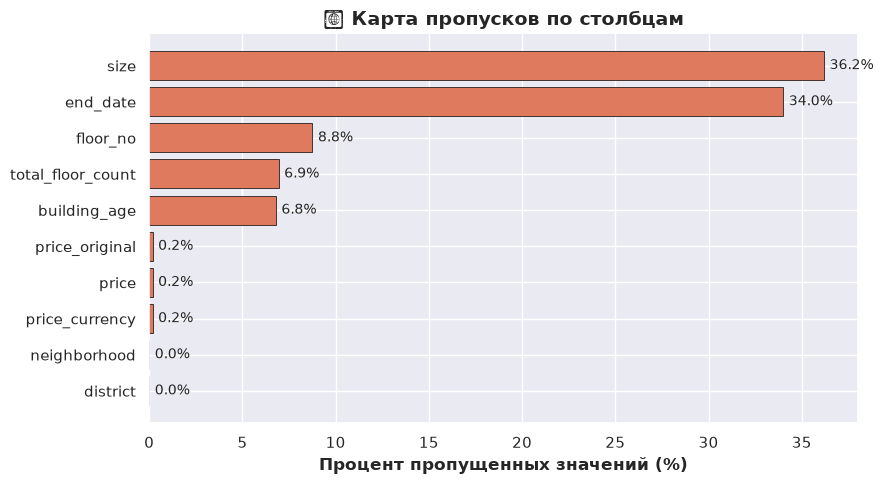

In [8]:
# График 1: Горизонтальная столбчатая диаграмма пропусков
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(miss_df.index, miss_df['Процент (%)'], color='#e07a5f', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Процент пропущенных значений (%)', fontweight='bold')
ax.set_title('🕳 Карта пропусков по столбцам', fontweight='bold', fontsize=14)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=10)
plt.tight_layout()
plt.show()

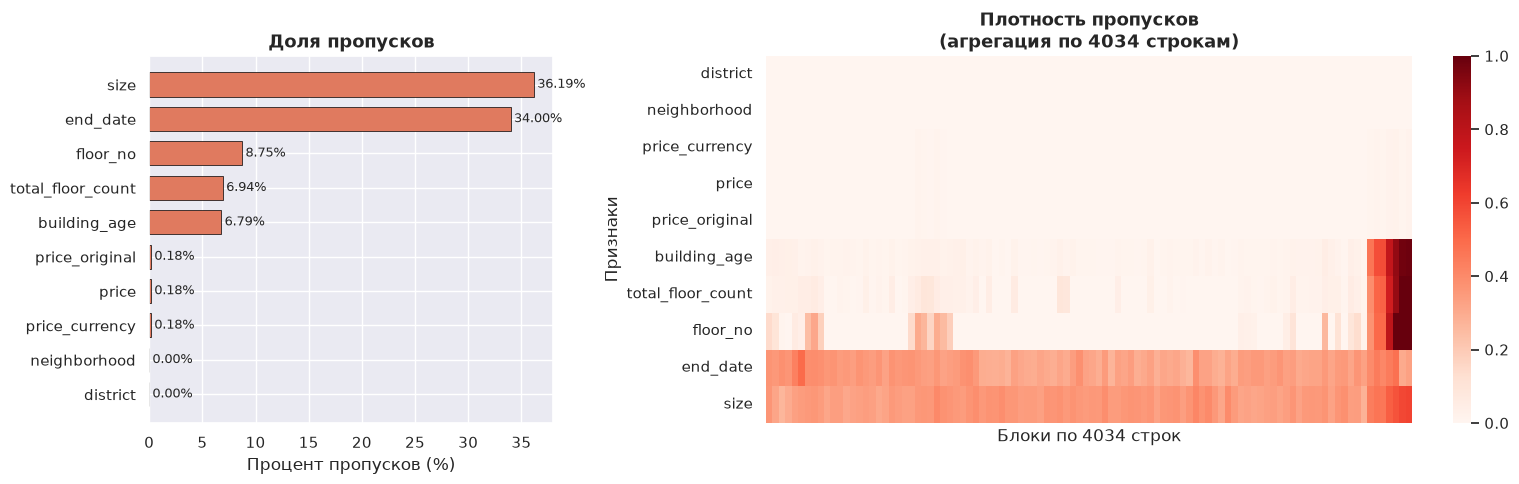


Всего столбцов с пропусками: 10 из 19
Столбец с максимальными пропусками: size (36.2%)
Столбцы без пропусков: 9


In [9]:
missing_cols = [col for col in miss_df.index if col in df.columns]

fig, axes = plt.subplots(1, 2, figsize=(16, 5),
                         gridspec_kw={'width_ratios': [1, 2]})

bars = axes[0].barh(range(len(missing_cols)),
                    miss_df['Процент (%)'].values,
                    color='#e07a5f', edgecolor='black', linewidth=0.5, height=0.7)
axes[0].set_yticks(range(len(missing_cols)))
axes[0].set_yticklabels(missing_cols)
axes[0].set_xlabel('Процент пропусков (%)')
axes[0].set_title('Доля пропусков', fontweight='bold', fontsize=13)

# Подписи значений на барах
for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 0.3, bar.get_y() + bar.get_height() / 2, f'{w:.2f}%', va='center', fontsize=9)

# Бинарная матрица: 1 = пропуск, 0 = есть значение. Агрегируем по блокам строк
# (в исходном порядке файла), чтобы увидеть, нет ли «полос» пропусков.
n_blocks = 100
block_size = max(len(df) // n_blocks, 1)
n_blocks = len(df) // block_size
df_sample = df.iloc[:n_blocks * block_size]

missing_matrix = df_sample[missing_cols].isnull().astype(int)
missing_agg = missing_matrix.values.reshape(n_blocks, block_size, len(missing_cols)).mean(axis=1)

sns.heatmap(missing_agg.T, ax=axes[1],
            cbar=True, cmap='Reds',
            yticklabels=missing_cols,
            xticklabels=False,
            vmin=0, vmax=1)

axes[1].set_title(f'Плотность пропусков\n(агрегация по {block_size} строкам)',
                  fontweight='bold', fontsize=13)
axes[1].set_ylabel('Признаки')
axes[1].set_xlabel(f'Блоки по {block_size} строк')

plt.tight_layout()
plt.show()

print(f"\nВсего столбцов с пропусками: {len(missing_cols)} из {len(df.columns)}")
print(f"Столбец с максимальными пропусками: {missing_cols[-1]} ({miss_df.iloc[-1]['Процент (%)']:.1f}%)")
print(f"Столбцы без пропусков: {len(df.columns) - len(missing_cols)}")


### Обработка пропусков

Пропуски обрабатываются в зависимости от типа признака.

Для числовых признаков используется заполнение медианой. Для категориальных признаков используется отдельная категория для неизвестных значений. Столбцы, которые не используются при обучении, исключаются.

Такой вариант позволяет сохранить большую часть исходных наблюдений.

## 4. Визуальный анализ распределений

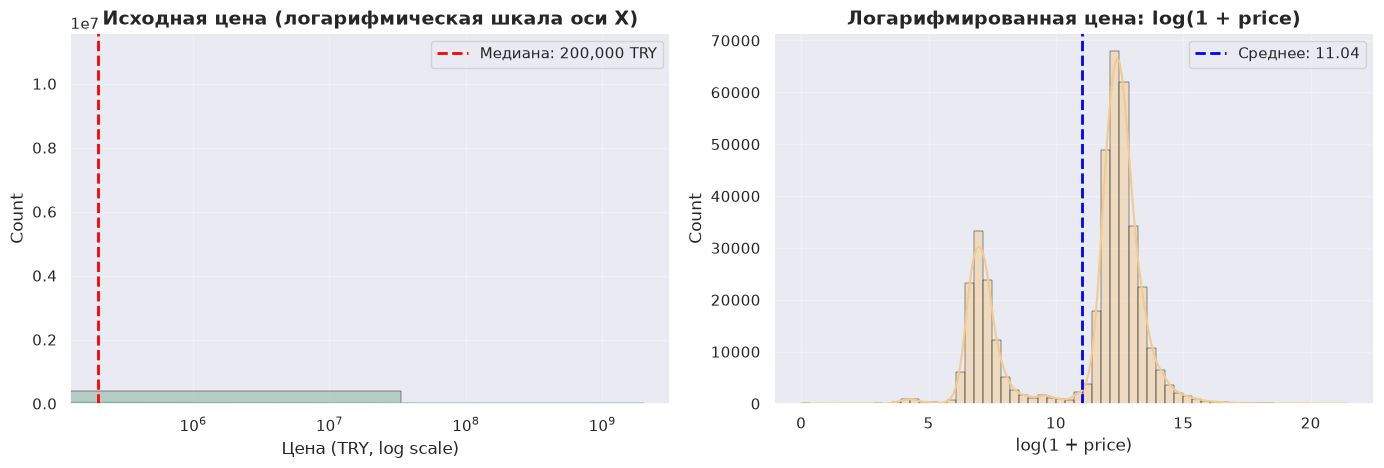

Асимметрия (Skewness) исходной price:      301.81
Асимметрия (Skewness) логарифмированной:   nan


In [10]:
# График 3: Распределение цены (до и после логарифмирования)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

prices_clean = df['price'].dropna()

# 1. Исходная цена с логарифмической шкалой оси X
sns.histplot(prices_clean, bins=60, kde=True, ax=axes[0], 
             color='#81b29a', edgecolor='black', linewidth=0.3)
axes[0].set_xscale('log')
axes[0].set_title('Исходная цена (логарифмическая шкала оси X)', fontweight='bold')
axes[0].set_xlabel('Цена (TRY, log scale)')
axes[0].axvline(prices_clean.median(), color='red', ls='--', lw=2, 
                label=f'Медиана: {prices_clean.median():,.0f} TRY')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Логарифмированная цена (линейная шкала)
log_prices = np.log1p(prices_clean)
sns.histplot(log_prices, bins=60, kde=True, ax=axes[1], 
             color='#f2cc8f', edgecolor='black', linewidth=0.3)
axes[1].set_title('Логарифмированная цена: log(1 + price)', fontweight='bold')
axes[1].set_xlabel('log(1 + price)')
axes[1].axvline(log_prices.mean(), color='blue', ls='--', lw=2, 
                label=f'Среднее: {log_prices.mean():.2f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Вывод метрик асимметрии
print(f"Асимметрия (Skewness) исходной price:      {skew(prices_clean):.2f}")
print(f"Асимметрия (Skewness) логарифмированной:   {skew(log_prices):.2f}")

### Распределение целевой переменной

Цена недвижимости имеет выраженную правостороннюю асимметрию. Поэтому перед обучением моделей используется преобразование:

`log_price = log1p(price)`

После обучения прогноз переводится обратно в исходную шкалу через `expm1`.

In [11]:
df['log_price'] = np.log1p(df['price'])

print("Асимметрия распределений:")
print(f"   • price:      skew = {skew(df['price'].dropna()):.2f}  (экстремальная правосторонняя)")
print(f"   • log_price:  skew = {skew(df['log_price'].dropna()):.2f}  (близко к нормальному)")
print()
print(f"Вывод: логарифмирование снизило асимметрию с {skew(df['price'].dropna()):.2f} до {skew(df['log_price'].dropna()):.2f}.")
print("   Это критически важно для линейных моделей (Ridge).")

Асимметрия распределений:
   • price:      skew = 301.81  (экстремальная правосторонняя)
   • log_price:  skew = -0.81  (близко к нормальному)

Вывод: логарифмирование снизило асимметрию с 301.81 до -0.81.
   Это критически важно для линейных моделей (Ridge).


 Асимметрия price:      301.81
 Асимметрия log_price:  -0.81


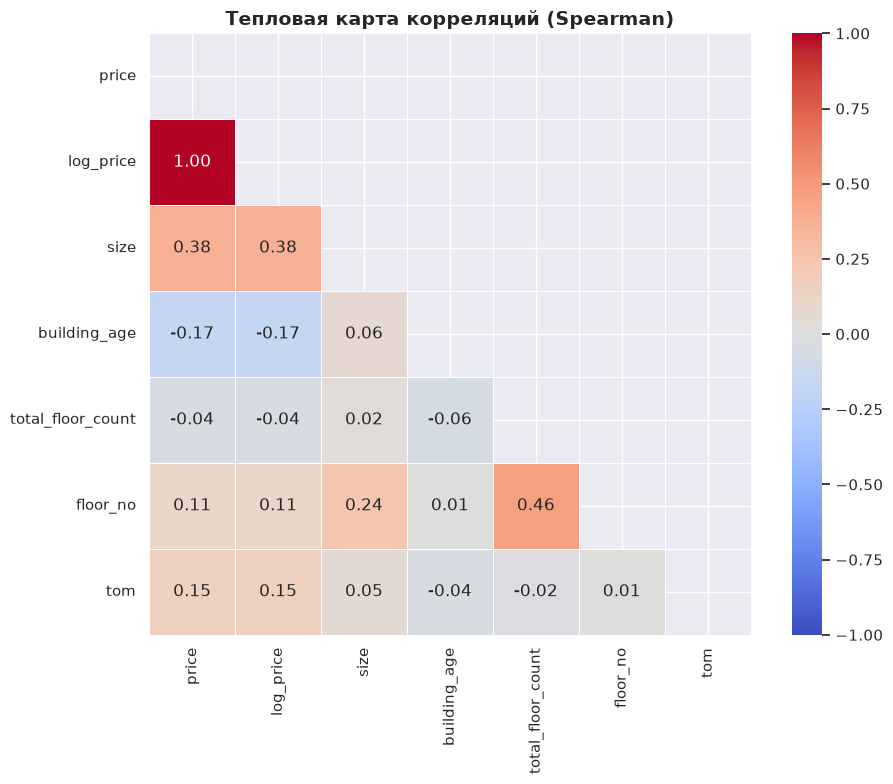


📌 Сильные корреляции (>0.5):
  price ↔ log_price: 1.000


In [12]:
df['log_price'] = np.log1p(df['price'])

print(f" Асимметрия price:      {skew(df['price'].dropna()):.2f}")
print(f" Асимметрия log_price:  {skew(df['log_price'].dropna()):.2f}")

# building_age / total_floor_count / floor_no — текст ('6-10 лет', '20 и более', ...).
# pd.to_numeric(errors='coerce') превращал ВСЕ диапазоны в NaN, поэтому разбираем парсерами.
_floor = map_unique(df['floor_no'], parse_floor_no)
corr_df = pd.DataFrame({
    'price': df['price'],
    'log_price': df['log_price'],
    'size': df['size'].where(df['size'].between(10, 1000)),
    'building_age': map_unique(df['building_age'], parse_building_age),
    'total_floor_count': map_unique(df['total_floor_count'], parse_total_floors),
    'floor_no': _floor.where(_floor != TOP_FLOOR),
    'tom': df['tom'],
})

# Spearman: цена и площадь тяжелохвостые, Пирсон на них показывает не то, что нужно.
corr_matrix = corr_df.corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True)
plt.title('Тепловая карта корреляций (Spearman)',
          fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

print("\n📌 Сильные корреляции (>0.5):")
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.5:
            print(f"  {corr_matrix.columns[i]} ↔ {corr_matrix.columns[j]}: {val:.3f}")


In [13]:
# Находим все пары с |r| > 0.3
strong_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.3:
            strong_corr.append((corr_matrix.columns[i], 
                               corr_matrix.columns[j], val))

# Сортируем по абсолютному значению
strong_corr.sort(key=lambda x: abs(x[2]), reverse=True)

print("\n🔗 Сильные и умеренные корреляции (|r| > 0.3):")
print("-" * 70)

for col1, col2, val in strong_corr:
    # Определяем силу связи
    if abs(val) >= 0.7:
        strength = " СИЛЬНАЯ"
    elif abs(val) >= 0.5:
        strength = " УМЕРЕННАЯ"
    else:
        strength = "🟡 СЛАБАЯ"
    
    direction = "положительная" if val > 0 else "отрицательная"
    print(f"  {strength} | {col1} ↔ {col2}: r = {val:+.3f} ({direction})")


🔗 Сильные и умеренные корреляции (|r| > 0.3):
----------------------------------------------------------------------
   СИЛЬНАЯ | price ↔ log_price: r = +1.000 (положительная)
  🟡 СЛАБАЯ | total_floor_count ↔ floor_no: r = +0.463 (положительная)
  🟡 СЛАБАЯ | price ↔ size: r = +0.383 (положительная)
  🟡 СЛАБАЯ | log_price ↔ size: r = +0.383 (положительная)


> **Вывод:** распределение цены имеет длинный правый хвост, поэтому для обучения используется логарифмированная целевая переменная.

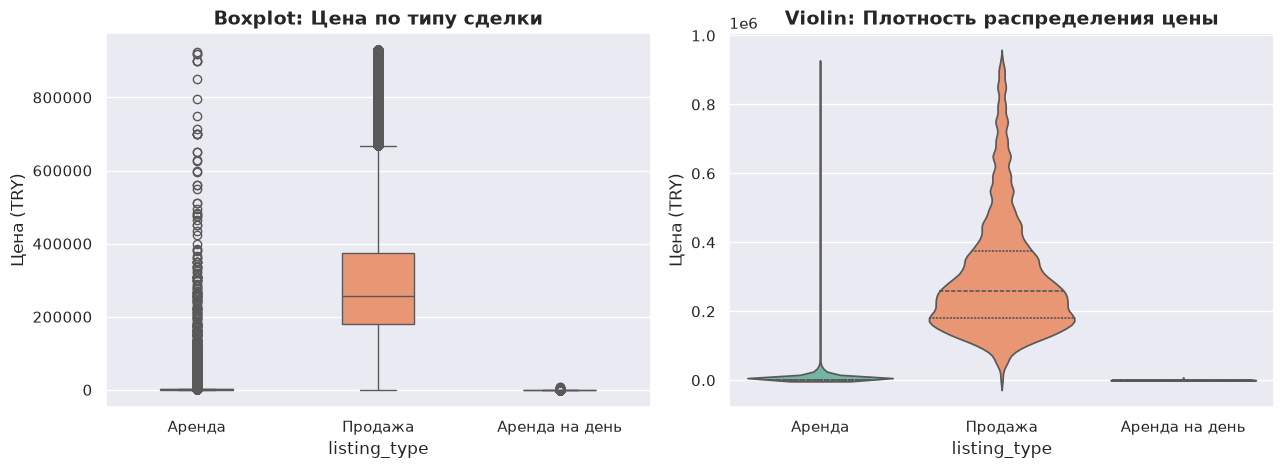

In [14]:
# График 4: Boxplot + Violin plot цены по типу сделки
price_cap = df['price'].quantile(0.95)
df_vis = df[df['price'] <= price_cap].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot
sns.boxplot(data=df_vis, x='listing_type', y='price', ax=axes[0], 
            palette='Set2', width=0.4)
axes[0].set_title('Boxplot: Цена по типу сделки', fontweight='bold')
axes[0].set_ylabel('Цена (TRY)')

# Violin plot
sns.violinplot(data=df_vis, x='listing_type', y='price', ax=axes[1], 
               palette='Set2', inner='quartile')
axes[1].set_title('Violin: Плотность распределения цены', fontweight='bold')
axes[1].set_ylabel('Цена (TRY)')

plt.tight_layout()
plt.show()

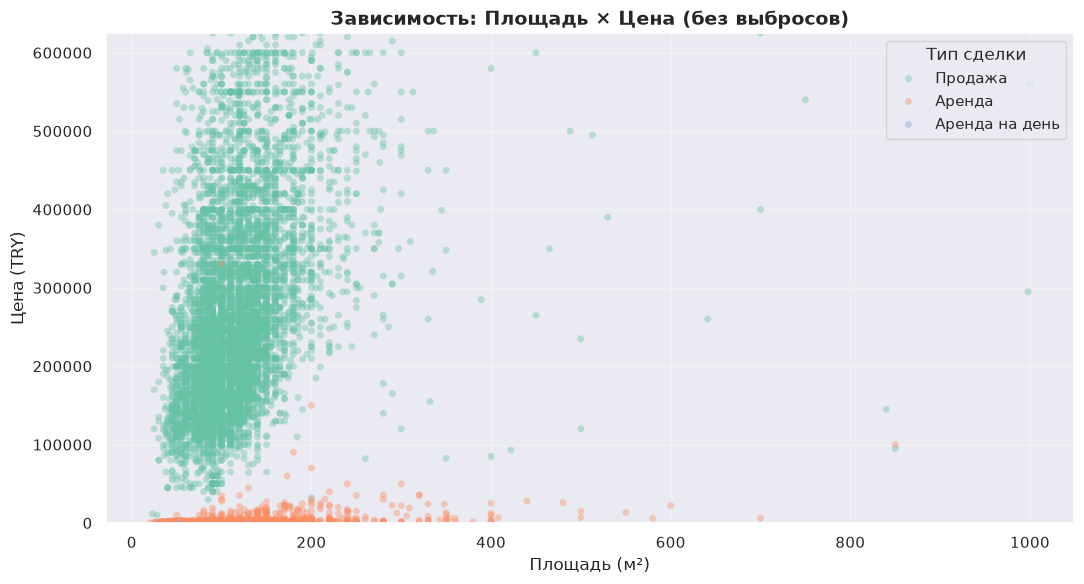

На графике: 10,000 точек
Диапазон площади: 20 – 1000 м²
Диапазон цены: 0 – 625,000 TRY (95-й перцентиль)


In [15]:
# 1. Фильтруем нереалистичные выбросы площади (оставляем разумный диапазон)
df_plot = df_vis[(df_vis['size'] >= 20) & (df_vis['size'] <= 1000)].copy()

# 2. Берём случайную выборку для скорости отрисовки
sample = df_plot.sample(min(10000, len(df_plot)), random_state=7)

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=sample,
    x='size',
    y='price',
    alpha=0.4,
    hue='listing_type',
    palette='Set2',
    s=25,
    edgecolor='none'
)

plt.title('Зависимость: Площадь × Цена (без выбросов)', fontweight='bold', fontsize=14)
plt.xlabel('Площадь (м²)', fontsize=12)
plt.ylabel('Цена (TRY)', fontsize=12)

# Ограничиваем ось Y разумным диапазоном (95-й перцентиль)
y_max = sample['price'].quantile(0.95)
plt.ylim(0, y_max)

plt.legend(title='Тип сделки')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Подпись с количеством точек
print(f"На графике: {len(sample):,} точек")
print(f"Диапазон площади: {sample['size'].min():.0f} – {sample['size'].max():.0f} м²")
print(f"Диапазон цены: 0 – {y_max:,.0f} TRY (95-й перцентиль)")

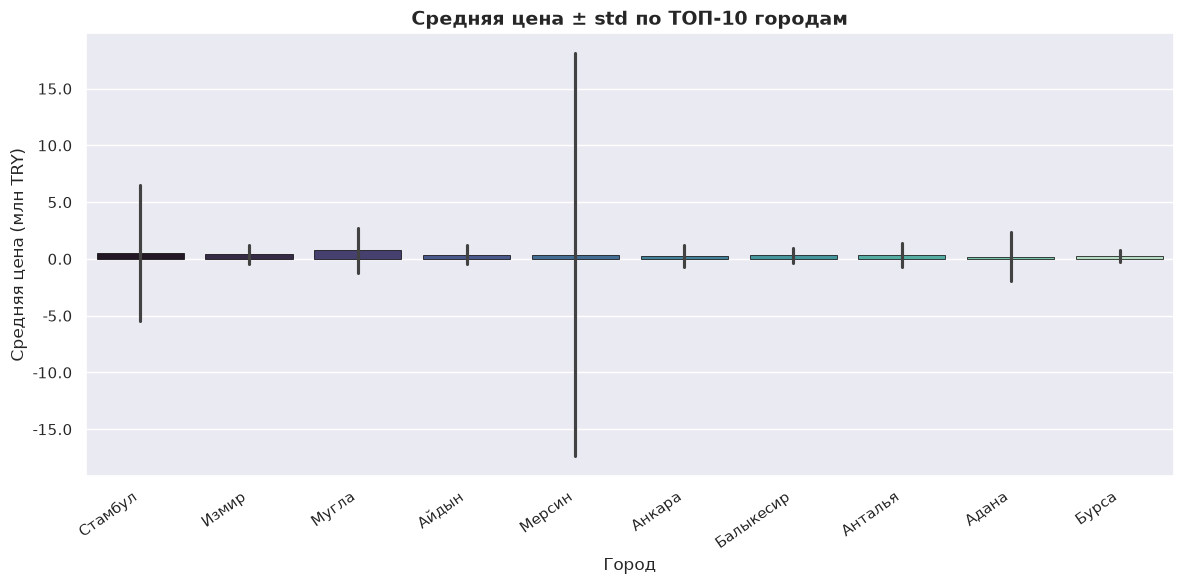

In [16]:
top10_cities = df['city'].value_counts().head(10).index
df_top = df[df['city'].isin(top10_cities)].copy()

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_top, 
    x='city', 
    y='price', 
    errorbar='sd', 
    palette='mako', 
    edgecolor='black', 
    linewidth=0.5
)

plt.title('Средняя цена ± std по ТОП-10 городам', fontweight='bold', fontsize=14)
plt.xlabel('Город', fontsize=12)
plt.ylabel('Средняя цена (млн TRY)', fontsize=12)

# Форматируем ось Y в миллионы для читаемости
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1e6:.1f}'))

plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

> **Вывод:** стоимость объектов заметно отличается между городами. Поэтому географические признаки сохраняются в модели.

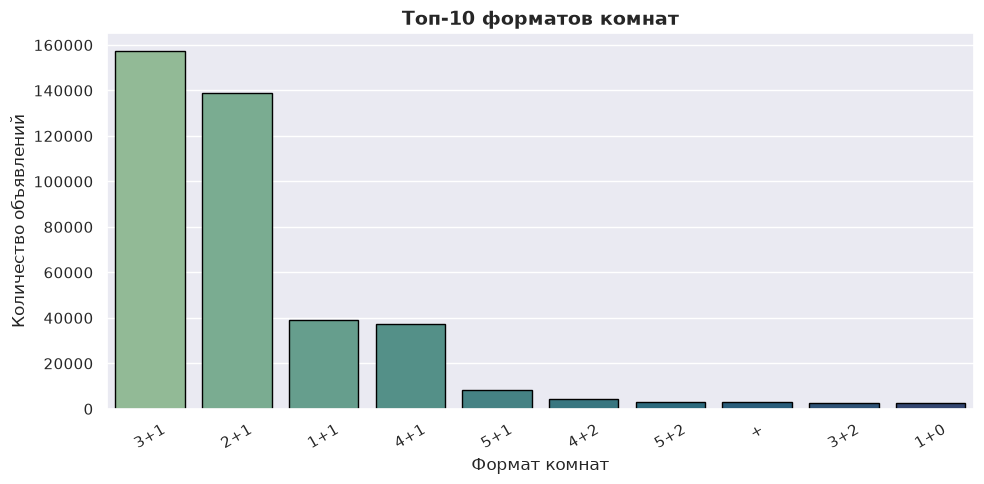

In [17]:
# График 7: Countplot — Распределение по количеству комнат
plt.figure(figsize=(10, 5))
order = df['room_count'].value_counts().head(10).index
sns.countplot(data=df, x='room_count', order=order, palette='crest', edgecolor='black')
plt.title('Топ-10 форматов комнат', fontweight='bold')
plt.xlabel('Формат комнат')
plt.ylabel('Количество объявлений')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

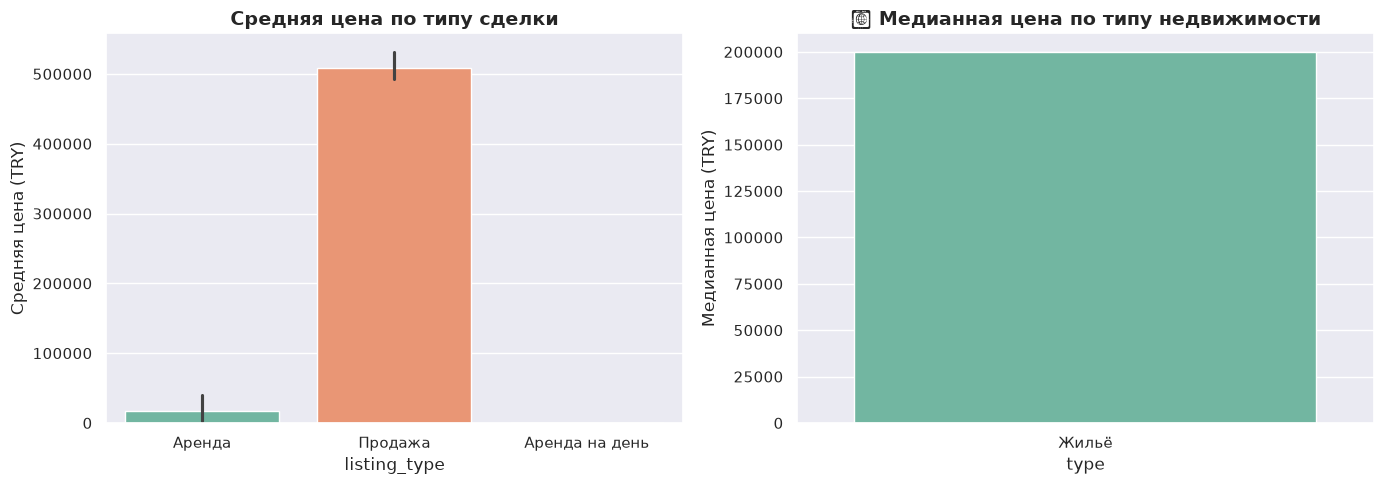

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# По типу сделки
sns.barplot(data=df, x='listing_type', y='price', 
            estimator='mean', errorbar='ci', palette='Set2', ax=axes[0])
axes[0].set_title('Средняя цена по типу сделки', fontweight='bold')
axes[0].set_ylabel('Средняя цена (TRY)')
axes[0].ticklabel_format(style='plain', axis='y')

# По типу недвижимости
sns.barplot(data=df, x='type', y='price', 
            estimator='median', errorbar=None, palette='Set2', ax=axes[1])
axes[1].set_title('🏠 Медианная цена по типу недвижимости', fontweight='bold')
axes[1].set_ylabel('Медианная цена (TRY)')
axes[1].ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

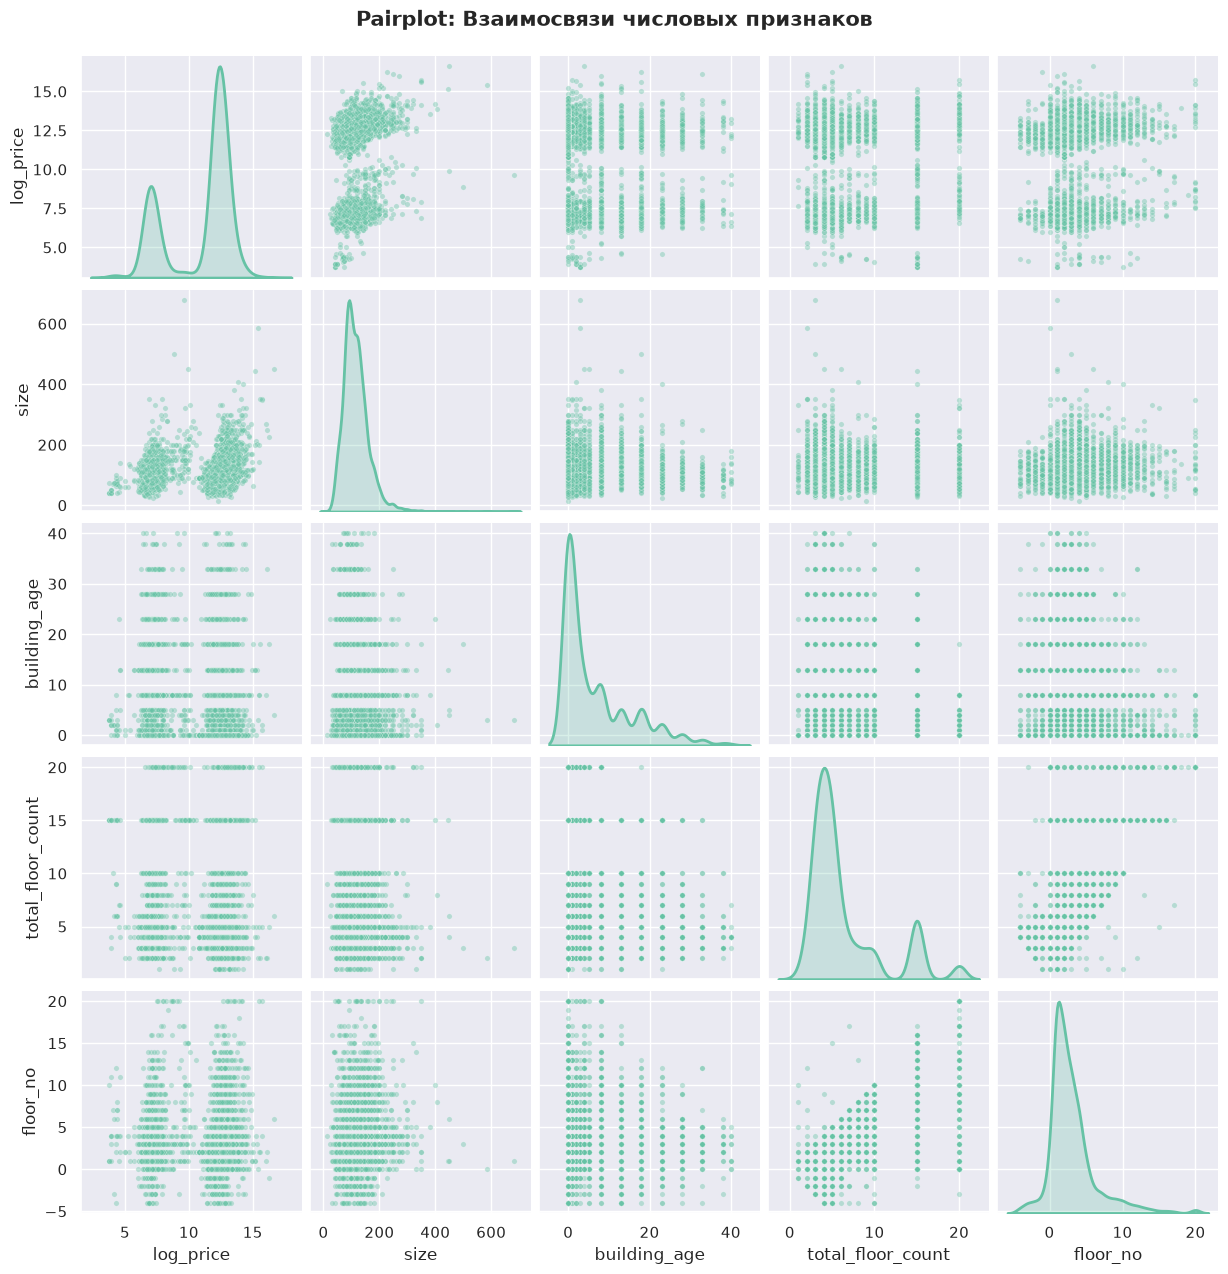

In [19]:
# График 8: Pairplot ключевых числовых признаков
# Берём уже разобранные числовые версии (в df эти столбцы текстовые).
cols_pair = ['log_price', 'size', 'building_age', 'total_floor_count', 'floor_no']
df_pair = corr_df[cols_pair].dropna()
df_pair = df_pair.sample(min(5000, len(df_pair)), random_state=RANDOM_STATE)

g = sns.pairplot(df_pair, diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15},
                 diag_kws={'linewidth': 2})
g.figure.suptitle('Pairplot: Взаимосвязи числовых признаков', y=1.02, fontsize=15, fontweight='bold')
plt.show()


### Основные гипотезы

1. Площадь объекта связана с его стоимостью.
2. Местоположение влияет на цену.
3. Количество комнат и характеристики здания могут улучшать прогноз.
4. Логарифмирование цены уменьшает влияние очень дорогих объектов.
5. Ансамбль деревьев должен работать лучше одиночного дерева на таком наборе признаков.

### Описательная статистика

По числовым признакам рассчитываются среднее, медиана, стандартное отклонение, минимальное и максимальное значения.

При сравнении среднего и медианы видно, что цена и площадь имеют несимметричные распределения. Это подтверждает необходимость дополнительной обработки выбросов перед обучением.

---
### Этап 2. Предварительная обработка данных

### 2.1 Обработка аномальных значений и пропусков

Основные правила обработки:
- отрицательные и нулевые цены удаляются;
- явно нереалистичные значения площади переводятся в пропуски;
- числовые пропуски заполняются медианой;
- пропуски в категориальных признаках заменяются отдельным значением;
- `address` напрямую в модель не передаётся.

In [20]:
# 2.2 Обработка выбросов и аномалий
# Важно: целевую переменную price НЕ винсоризуем — иначе изменяются реальные
# значения, по которым оценивается качество прогноза.
# Для площади используем логическое ограничение предметной области.

df_tr = df.copy()

# Невозможные значения цены не удаляем заранее по статистическому порогу:
# только явно некорректные значения переводим в NaN.
df_tr.loc[df_tr['price'] <= 0, 'price'] = np.nan

# Явно нереалистичные значения площади переводим в пропуски.
df_tr.loc[(df_tr['size'] < 10) | (df_tr['size'] > 1000), 'size'] = np.nan

print("✅ Аномалии обработаны без изменения распределения целевой переменной.")
print(f"Пропусков price после проверки: {df_tr['price'].isna().sum()}")
print(f"Пропусков size после проверки: {df_tr['size'].isna().sum()}")

✅ Аномалии обработаны без изменения распределения целевой переменной.
Пропусков price после проверки: 760
Пропусков size после проверки: 147078


In [21]:
# 2.1 Подготовка данных (EDA-копия df_tr)
# Текст -> числа теми же функциями, которые работают внутри Pipeline.
# Старый код делал pd.to_numeric(errors='coerce') ДО словаря возрастов: '6-10 лет' -> NaN,
# и словарь потом ничего не находил (в building_age оставалось всего 6 значений).
for col, fn in [('building_age', parse_building_age),
                ('total_floor_count', parse_total_floors)]:
    df_tr[col] = map_unique(df[col], fn)

_floor = map_unique(df['floor_no'], parse_floor_no)
_is_top = _floor == TOP_FLOOR                      # мансарда / последний этаж
df_tr['floor_no'] = _floor.where(~_is_top, df_tr['total_floor_count'])
df_tr['is_top_floor'] = _is_top.astype('float32')

# Диагностика: значения, которые парсер не смог разобрать (проверьте глазами).
for col, fn in [('building_age', parse_building_age),
                ('total_floor_count', parse_total_floors),
                ('floor_no', parse_floor_no)]:
    parsed = map_unique(df[col], fn)
    bad = df.loc[df[col].notna() & parsed.isna(), col].value_counts().head(10)
    print(f"{col}: уникальных после разбора = {df_tr[col].nunique()}, не разобрано: {int(bad.sum())}")
    if len(bad):
        print(bad.to_string())

print(f"\nРазмер после первичной очистки: {df_tr.shape}")
print("Заполнение пропусков будет выполнено только на train в Pipeline.")


building_age: уникальных после разбора = 14, не разобрано: 0
total_floor_count: уникальных после разбора = 12, не разобрано: 0
floor_no: уникальных после разбора = 25, не разобрано: 24428
floor_no
Отдельный          21165
Целиком             2958
Этаж с террасой      293
Антресоль             12

Размер после первичной очистки: (403487, 21)
Заполнение пропусков будет выполнено только на train в Pipeline.


### 2.2 Создание дополнительных признаков

Из исходных текстовых полей формируются признаки, которые удобнее использовать в модели.

В частности, формат комнат преобразуется в числовой признак `rooms_numeric`. Для числовых характеристик здания используются подготовленные значения, после чего они передаются в общий pipeline.

In [22]:
# 2.4 Feature Engineering (EDA-версия; в модели то же самое делает RealEstateFeatures)
df_tr['rooms_numeric'] = map_unique(df_tr['room_count'], parse_rooms)

# price_per_sqm — только для EDA, в модель НЕ передаётся (считается из target).
df_tr['price_per_sqm'] = df_tr['price'] / df_tr['size']

# NaN <= 5 даёт False и маскировал пропуск как «старый дом» — сохраняем NaN.
df_tr['is_new_building'] = (df_tr['building_age'] <= 5).astype('float32').where(df_tr['building_age'].notna(), np.nan)
df_tr['floor_ratio'] = df_tr['floor_no'] / df_tr['total_floor_count'].replace(0, np.nan)

# Целевая переменная для обучения.
df_tr['log_price'] = np.log1p(df_tr['price'])

print("✅ Созданы rooms_numeric, is_new_building, floor_ratio, is_top_floor и log_price.")
print("⚠️ price_per_sqm используется только для анализа и исключается из признаков модели.")


✅ Созданы rooms_numeric, is_new_building, floor_ratio, is_top_floor и log_price.


⚠️ price_per_sqm используется только для анализа и исключается из признаков модели.


### 2.3 Проверка признаков

Для числовых признаков дополнительно проверяется взаимосвязь между переменными.

Наличие корреляции между площадью и количеством комнат является ожидаемым. Для Random Forest такая зависимость не является критической проблемой, поэтому признаки сохраняются.

In [23]:
from statsmodels.tools.tools import add_constant

vif_cols = ['size', 'building_age', 'total_floor_count', 'floor_no', 'rooms_numeric']
X_vif = df_tr[vif_cols].dropna()
X_vif = X_vif.sample(min(50000, len(X_vif)), random_state=RANDOM_STATE)

# VIF считается с константой, иначе значения завышены.
X_vif_c = add_constant(X_vif)
vif_df = pd.DataFrame({
    'Признак': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif_c.values, i + 1) for i in range(X_vif.shape[1])]
}).sort_values('VIF', ascending=False)

print("📊 Коэффициенты инфляции дисперсии (VIF):")
display(vif_df.style.format({'VIF': '{:.2f}'}))


📊 Коэффициенты инфляции дисперсии (VIF):


,Признак,VIF
0,size,2.92
4,rooms_numeric,2.90
3,floor_no,1.71
2,total_floor_count,1.70
1,building_age,1.02


> **Вывод:** часть признаков связана между собой, но для модели на основе деревьев это допустимо.

### 2.4 Кодирование категориальных признаков

Категориальные признаки преобразуются с помощью `OneHotEncoder`.

Кодирование выполняется внутри `Pipeline`, поэтому параметры преобразования рассчитываются только на обучающей выборке.

### Разбиение и подготовка данных

Сначала выполняется разделение на train, validation и test. После этого препроцессор обучается только на train.

Это позволяет использовать validation и test только для оценки уже обученных моделей.

### Подготовка категориальных признаков

Для категориальных столбцов используется единый препроцессор `ColumnTransformer`.

Одинаковая схема преобразования применяется к train, validation и test.

### 2.5 Масштабирование числовых признаков

Для числовых признаков используется `RobustScaler`.

Он менее чувствителен к выбросам, чем стандартное масштабирование. Для Random Forest масштабирование не является обязательным, но общий pipeline используется для единообразной подготовки данных и сравнения моделей.

---
### Этап 3. Построение модели регрессии

Для сравнения используются три модели:
1. Ridge;
2. Decision Tree;
3. Random Forest.

После базового сравнения выполняется подбор параметров и выбирается модель с лучшим результатом на validation.

In [24]:
# Подготовка выборки и разбиение 70/15/15
from sklearn.model_selection import train_test_split

TARGET = 'log_price'

# 1) Только объекты с корректной ценой (price уже в TRY; NaN и <=0 отбрасываются).
model_df = df[df['price'] > 0].copy()
model_df[TARGET] = np.log1p(model_df['price'])

# 2) Дубликаты. Одно и то же объявление, выложенное повторно, при случайном split попадает
# и в train, и в test -> завышенный R². id уникален, поэтому сравниваем без id/tom/дат.
dup_cols = [c for c in model_df.columns
            if c not in ('id', 'tom', 'start_date', 'end_date', 'price_original', TARGET)]
n_before = len(model_df)
model_df = model_df.drop_duplicates(subset=dup_cols)
print(f"Удалено дубликатов объявлений: {n_before - len(model_df):,}")

# 3) В модель идут только признаки, известные в момент публикации.
# tom, end_date — это будущее (leakage); id — просто номер; price_per_sqm — из target.
X_raw = model_df[RAW_FEATURES]
y = model_df[TARGET]

X_train, X_temp, y_train, y_temp = train_test_split(
    X_raw, y, test_size=0.30, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

# 4) Подрезка выбросов цены ТОЛЬКО в train (по квантилам внутри типа сделки).
# Опечатки вида «цена 1 TRY» или «2 млрд» не должны диктовать модели правила.
# Validation/test не трогаем — качество измеряется на «грязных» данных.
TRIM_TRAIN_OUTLIERS = True
if TRIM_TRAIN_OUTLIERS:
    grp = y_train.groupby(X_train['listing_type'].fillna('Unknown'))
    lo = grp.transform(lambda s: s.quantile(0.005))
    hi = grp.transform(lambda s: s.quantile(0.995))
    keep = (y_train >= lo) & (y_train <= hi)
    print(f"Подрезано выбросов в train: {(~keep).sum():,} ({(~keep).mean()*100:.2f}%)")
    X_train, y_train = X_train[keep], y_train[keep]

print(f"Train: {X_train.shape[0]:,}")
print(f"Validation: {X_val.shape[0]:,}")
print(f"Test: {X_test.shape[0]:,}")
print(f"random_state = {RANDOM_STATE}")


Удалено дубликатов объявлений: 111,715


Подрезано выбросов в train: 1,846 (0.91%)
Train: 201,862
Validation: 43,652
Test: 43,652
random_state = 42


In [25]:
# Препроцессинг БЕЗ утечки данных
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, TargetEncoder
from sklearn.base import clone

numeric_cols = NUM_COLS
categorical_cols = LOWCARD_COLS + HIGHCARD_COLS

def make_preprocessor():
    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])
    # Малокардинальные признаки -> One-Hot (редкие категории группируются).
    onehot = OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=50,
        sparse_output=False,
        dtype=np.float32
    )
    # Город/район/микрорайон (4834 значения) -> Target Encoding с кросс-фиттингом (cv=5):
    # для каждой строки train значение считается по другим фолдам, поэтому target не утекает.
    # Ключи включают тип сделки (продажа и аренда различаются по цене ~в 100 раз).
    # Одинаковые названия микрорайонов в разных районах больше не склеиваются.
    geo = TargetEncoder(target_type='continuous', smooth='auto', cv=5, random_state=RANDOM_STATE)

    return ColumnTransformer(
        transformers=[
            ('num', numeric_pipe, NUM_COLS),
            ('low', onehot, LOWCARD_COLS),
            ('geo', geo, HIGHCARD_COLS),
        ],
        remainder='drop',
        sparse_threshold=0.0
    )

def make_pipeline(estimator):
    return Pipeline([
        ('features', RealEstateFeatures()),   # парсинг сырых столбцов + заполнение size по train
        ('preprocessor', make_preprocessor()),
        ('model', estimator)
    ])

print(f"Числовых признаков: {len(numeric_cols)}")
print(f"Категориальных признаков: {len(categorical_cols)}")
print("✅ Медианы, частоты, OHE и Target Encoding обучаются только на train.")


Числовых признаков: 18
Категориальных признаков: 8
✅ Медианы, частоты, OHE и Target Encoding обучаются только на train.


### 3.1 Базовое сравнение моделей

Сначала модели обучаются с базовыми параметрами. Это позволяет получить исходную точку для дальнейшего подбора гиперпараметров.

In [26]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models_base = {
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    ),
    'RandomForest': RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=3,
        max_features=0.5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingRegressor(
        learning_rate=0.1,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=RANDOM_STATE
    )
}

base_results = []

for name, estimator in models_base.items():
    pipe = make_pipeline(estimator)
    pipe.fit(X_train, y_train)
    pred_val = pipe.predict(X_val)
    pred_tr = pipe.predict(X_train)

    base_results.append({
        'Model': name,
        'MAE_log': mean_absolute_error(y_val, pred_val),
        'RMSE_log': np.sqrt(mean_squared_error(y_val, pred_val)),
        'R2_train': r2_score(y_train, pred_tr),
        'R2_val': r2_score(y_val, pred_val)
    })

base_results_df = pd.DataFrame(base_results).sort_values('R2_val', ascending=False)
display(base_results_df)


,Model,MAE_log,RMSE_log,R2_train,R2_val
3,HistGradientBoosting,0.251519,0.445957,0.985565,0.971511
2,RandomForest,0.248731,0.451893,0.989726,0.970747
1,DecisionTree,0.281605,0.489154,0.982461,0.965724
0,Ridge,0.309369,0.507043,0.977197,0.963172


### 3.2 Подбор параметров

Для моделей используется `RandomizedSearchCV` с кросс-валидацией на обучающей выборке.

Validation и test не используются при подборе параметров.

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

# Подбор — по R² (именно его мы максимизируем), 3-fold CV, только на train.
# Для скорости ищем на подвыборке train, лучшие параметры затем переобучаем на ВСЁМ train.
TUNE_SAMPLE = 60_000
N_ITER = {'Ridge': 15, 'DecisionTree': 15, 'RandomForest': 8, 'HistGradientBoosting': 15}
FINAL_RF_TREES = 300

search_spaces = {
    'Ridge': {
        'model__alpha': loguniform(1e-2, 1e3)
    },
    'DecisionTree': {
        'model__max_depth': randint(8, 31),
        'model__min_samples_split': randint(10, 60),
        'model__min_samples_leaf': randint(5, 60)       # >=5: лист из 1 объекта = переобучение
    },
    'RandomForest': {
        'model__max_depth': randint(12, 31),
        'model__min_samples_split': randint(4, 20),
        'model__min_samples_leaf': randint(2, 12),
        'model__max_features': uniform(0.3, 0.5)         # 0.3 ... 0.8
    },
    'HistGradientBoosting': {
        'model__learning_rate': loguniform(0.03, 0.2),
        'model__max_leaf_nodes': randint(31, 255),
        'model__min_samples_leaf': randint(20, 200),
        'model__l2_regularization': loguniform(1e-3, 10),
        'model__max_features': uniform(0.5, 0.5)         # 0.5 ... 1.0
    }
}

X_tune = X_train.sample(min(TUNE_SAMPLE, len(X_train)), random_state=RANDOM_STATE)
y_tune = y_train.loc[X_tune.index]

best_models = {}
search_summary = []

for name, estimator in models_base.items():
    pipe = make_pipeline(clone(estimator))

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=search_spaces[name],
        n_iter=N_ITER[name],
        cv=3,
        scoring='r2',
        random_state=RANDOM_STATE,
        n_jobs=1,          # распараллеливание уже внутри RandomForest / HistGradientBoosting
        refit=False
    )

    print(f"🔄 Подбор параметров: {name}")
    search.fit(X_tune, y_tune)

    best_params = dict(search.best_params_)
    if name == 'RandomForest':
        best_params['model__n_estimators'] = FINAL_RF_TREES

    final_pipe = make_pipeline(clone(estimator)).set_params(**best_params)
    final_pipe.fit(X_train, y_train)            # финальное обучение на всём train
    best_models[name] = final_pipe

    search_summary.append({
        'Model': name,
        'Best_CV_R2': search.best_score_,
        'Best_params': best_params
    })

search_summary_df = pd.DataFrame(search_summary).sort_values('Best_CV_R2', ascending=False)
pd.set_option('display.max_colwidth', 200)
display(search_summary_df)


🔄 Подбор параметров: Ridge


🔄 Подбор параметров: DecisionTree


🔄 Подбор параметров: RandomForest


🔄 Подбор параметров: HistGradientBoosting


,Model,Best_CV_R2,Best_params
3,HistGradientBoosting,0.980696,"{'model__l2_regularization': 4.869640941520899, 'model__learning_rate': 0.03548387173121614, 'model__max_features': 0.5979914312095727, 'model__max_leaf_nodes': 220, 'model__min_samples_leaf': 59}"
2,RandomForest,0.979165,"{'model__max_depth': 27, 'model__max_features': 0.4163856702151521, 'model__min_samples_leaf': 4, 'model__min_samples_split': 15, 'model__n_estimators': 300}"
1,DecisionTree,0.973824,"{'model__max_depth': 23, 'model__min_samples_leaf': 19, 'model__min_samples_split': 56}"
0,Ridge,0.971346,{'model__alpha': 10.129197956845726}


### 3.3 Метрики качества

Для сравнения используются MAE, RMSE и R².

Основные метрики дополнительно рассчитываются после обратного преобразования цены из логарифмической шкалы в TRY.

In [28]:
def evaluate_regression(model, X, y_log, name):
    pred_log = model.predict(X)

    y_orig = np.expm1(np.asarray(y_log))
    pred_orig = np.maximum(np.expm1(pred_log), 0)

    mask = y_orig > 0
    ape = np.abs((y_orig[mask] - pred_orig[mask]) / y_orig[mask])
    return {
        'Model': name,
        'R2_log': r2_score(y_log, pred_log),
        'MAE_log': mean_absolute_error(y_log, pred_log),
        'RMSE_log': np.sqrt(mean_squared_error(y_log, pred_log)),
        # R² в лирах очень чувствителен к единичным выбросам цены — смотрите вместе с R2_log.
        'R2_TRY': r2_score(y_orig, pred_orig),
        'MAE_TRY': mean_absolute_error(y_orig, pred_orig),
        'RMSE_TRY': np.sqrt(mean_squared_error(y_orig, pred_orig)),
        'MAPE_%': np.mean(ape) * 100,
        'MedAPE_%': np.median(ape) * 100      # медиана устойчива к опечаткам в цене
    }

val_results = pd.DataFrame([
    evaluate_regression(model, X_val, y_val, name)
    for name, model in best_models.items()
])

display(val_results.sort_values('R2_log', ascending=False).reset_index(drop=True))


,Model,R2_log,MAE_log,RMSE_log,R2_TRY,MAE_TRY,RMSE_TRY,MAPE_%,MedAPE_%
0,HistGradientBoosting,0.972221,0.242957,0.440364,0.010715,170043.568241,8.124497e+06,91.701908,15.668097
1,RandomForest,0.970631,0.248595,0.452794,0.008569,174206.070655,8.133305e+06,91.936290,15.710589
2,DecisionTree,0.965766,0.281437,0.488858,0.009796,183712.293577,8.128271e+06,100.630162,18.222266
3,Ridge,0.963159,0.309407,0.507131,0.013020,189611.198252,8.115026e+06,96.806808,21.080364


In [29]:
# Проверка качества моделей
required_metrics = {'MAE_log', 'RMSE_log', 'R2_log', 'R2_TRY', 'MAE_TRY', 'RMSE_TRY', 'MAPE_%', 'MedAPE_%'}
missing_metrics = required_metrics - set(val_results.columns)

assert not missing_metrics, f"Не хватает метрик: {missing_metrics}"
assert np.isfinite(val_results[list(required_metrics)].to_numpy()).all(), "В метриках обнаружены NaN/inf."
assert len(val_results) == len(best_models), "Количество результатов не совпадает с количеством моделей."

print("✅ Проверка моделей пройдена: метрики рассчитаны для всех tuned-моделей.")


✅ Проверка моделей пройдена: метрики рассчитаны для всех tuned-моделей.


In [30]:
# Контроль переобучения: R² на train и validation + разрыв между ними.
idx = X_train.sample(min(50_000, len(X_train)), random_state=RANDOM_STATE).index
rows = []
for name, model in best_models.items():
    r2_tr = r2_score(y_train.loc[idx], model.predict(X_train.loc[idx]))
    r2_va = r2_score(y_val, model.predict(X_val))
    rows.append({'Model': name, 'R2_train': r2_tr, 'R2_val': r2_va, 'Gap': r2_tr - r2_va})

overfit_df = pd.DataFrame(rows).sort_values('R2_val', ascending=False).reset_index(drop=True)
display(overfit_df)

for _, r in overfit_df.iterrows():
    if r['Gap'] > 0.03:
        print(f"⚠️ {r['Model']}: разрыв train-val = {r['Gap']:.3f} — признак переобучения "
              "(усильте регуляризацию: min_samples_leaf, max_depth, l2_regularization).")


,Model,R2_train,R2_val,Gap
0,HistGradientBoosting,0.987478,0.972221,0.015257
1,RandomForest,0.988732,0.970631,0.018101
2,DecisionTree,0.982823,0.965766,0.017057
3,Ridge,0.977365,0.963159,0.014206


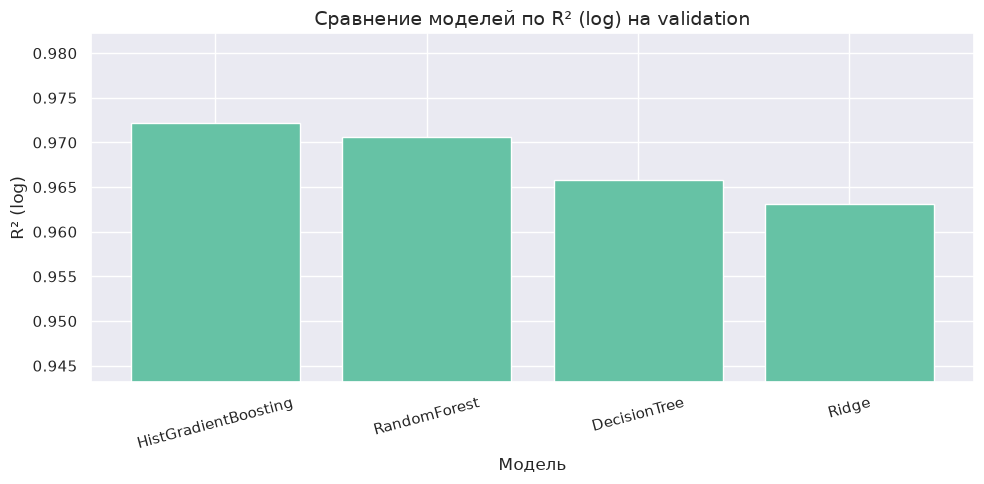

Рантинг моделей по validation R² (log):
  HistGradientBoosting   +0.9722
  RandomForest           +0.9706
  DecisionTree           +0.9658
  Ridge                  +0.9632

Лучший validation R² у модели HistGradientBoosting (0.9722), у Random Forest — 0.9706.
Финальной моделью проекта оставлен Random Forest — так задано в условии работы.


In [31]:
# Сравнение моделей и выбор финальной модели
# Критерий сравнения — R² (log) на validation. Test в выборе не участвует.
plot_df = val_results.sort_values('R2_log', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(plot_df['Model'], plot_df['R2_log'])
ax.set_ylim(max(plot_df['R2_log'].min() - 0.02, 0), min(plot_df['R2_log'].max() + 0.01, 1.0))
ax.set_title('Сравнение моделей по R² (log) на validation')
ax.set_ylabel('R² (log)')
ax.set_xlabel('Модель')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Рантинг моделей по validation R² (log):")
for _, r in plot_df.iterrows():
    print(f"  {r['Model']:<22} {r['R2_log']:+.4f}")

# Итоговой моделью проекта, по условию задания, является Random Forest — сохраняем её
# (раздел 3.5). Если по validation её обгоняет другая модель, это не скрываем:
# численные результаты всех моделей напечатаны выше.
best_name = 'RandomForest'
best_model = best_models[best_name]
rf_r2 = float(val_results.loc[val_results['Model'] == best_name, 'R2_log'].iloc[0])
auto_name = plot_df.loc[0, 'Model']
if auto_name == best_name:
    print(f'\nФинальная модель проекта: {best_name} (лучший validation R² = {rf_r2:.4f}).')
else:
    print(f"\nЛучший validation R² у модели {auto_name} ({plot_df.loc[0, 'R2_log']:.4f}), "
          f"у Random Forest — {rf_r2:.4f}.")
    print('Финальной моделью проекта оставлен Random Forest — так задано в условии работы.')


,Model,R2_log,MAE_log,RMSE_log,R2_TRY,MAE_TRY,RMSE_TRY,MAPE_%,MedAPE_%
0,RandomForest,0.971497,0.246335,0.444631,0.095232,142703.581937,1.980367e+06,80.532652,15.582355


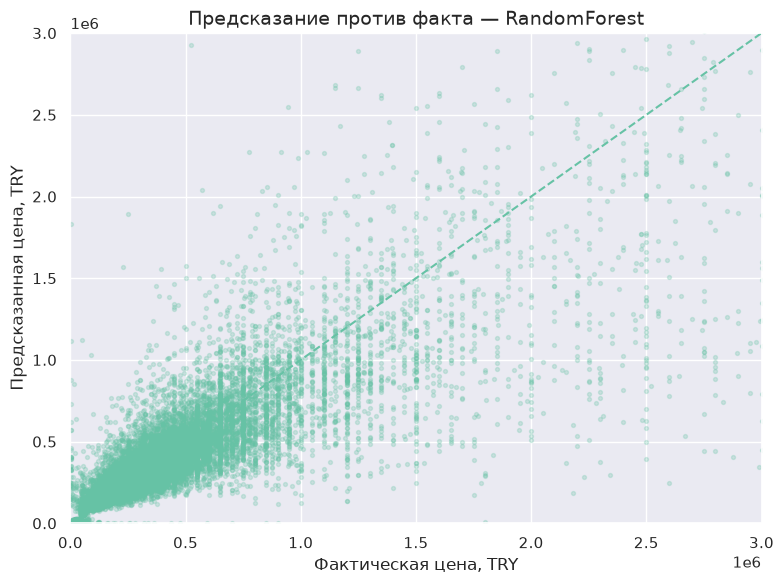

In [32]:
# Финальная проверка на отложенном test
test_result = pd.DataFrame([
    evaluate_regression(best_model, X_test, y_test, best_name)
])

display(test_result)

pred_test_log = best_model.predict(X_test)
y_test_orig = np.expm1(np.asarray(y_test))
pred_test_orig = np.maximum(np.expm1(pred_test_log), 0)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_orig, pred_test_orig, s=8, alpha=0.25)
lims = [0, np.percentile(y_test_orig, 99)]
plt.plot(lims, lims, linestyle='--')
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel('Фактическая цена, TRY')
plt.ylabel('Предсказанная цена, TRY')
plt.title(f'Предсказание против факта — {best_name}')
plt.tight_layout()
plt.show()


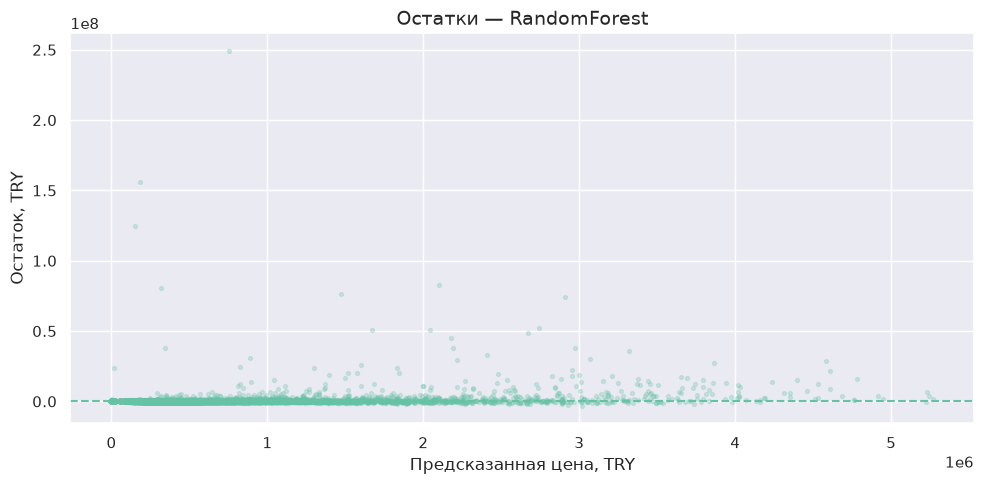

In [33]:
# Анализ остатков
residuals = y_test_orig - pred_test_orig

plt.figure(figsize=(10, 5))
plt.scatter(pred_test_orig, residuals, s=8, alpha=0.25)
plt.axhline(0, linestyle='--')
plt.xlabel('Предсказанная цена, TRY')
plt.ylabel('Остаток, TRY')
plt.title(f'Остатки — {best_name}')
plt.tight_layout()
plt.show()


### 3.5 Выбор итоговой модели

По условию задания итоговой моделью проекта выбран Random Forest; сравнение с остальными моделями приведено выше.

Сохраняется полный pipeline с подготовкой признаков и обученной моделью.

In [34]:
# Сохранение финальной модели
import joblib

joblib.dump(best_model, 'best_model_pipeline.pkl')

joblib.dump({
    'raw_features': RAW_FEATURES,
    'numeric_features': numeric_cols,
    'categorical_features': categorical_cols,
    'all_features': X_train.columns.tolist(),
    'target': 'log_price',
    'target_note': 'log1p(price в TRY); прогноз в лирах = expm1(predict)',
    'fx_to_try': FX_TO_TRY,
    'model_name': best_name
}, 'feature_schema.pkl')

print(f'✅ Сохранена финальная модель: {best_name}')
print('Файл модели: best_model_pipeline.pkl')
print('В Pipeline входят парсинг признаков, preprocessing и модель.')
print('⚠️ Для загрузки в приложении положите рядом файл real_estate_features.py.')


✅ Сохранена финальная модель: RandomForest
Файл модели: best_model_pipeline.pkl
В Pipeline входят парсинг признаков, preprocessing и модель.
⚠️ Для загрузки в приложении положите рядом файл real_estate_features.py.


---
### Этап 4. Применение модели

Обученная модель может использоваться для получения прогноза стоимости нового объекта.

Для работы приложения необходимо передавать те же признаки, которые использовались при обучении модели.

### Итоговые выводы

В работе проведён анализ данных о недвижимости Турции, выполнена очистка и подготовка признаков, после чего были обучены несколько регрессионных моделей.

По результатам сравнения выбрана модель Random Forest. Она сохраняется вместе с preprocessing в одном pipeline, что позволяет использовать ту же обработку признаков при дальнейшем прогнозировании.

---
### Этап 5. Проверка модели на тестовых объектах

На заключительном этапе модель проверяется на 20 тестовых объектах.

Для каждого объекта выводятся фактическая цена и прогноз. После этого рассчитываются MAE, RMSE и R² двумя способами: вручную и средствами `sklearn`.

In [35]:
# 5.1 Загрузка тестовых объектов и подготовка признаков
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

# Ищем тестовый файл в папке проекта и в data; если нет — создадим в папке проекта.
_test_name = "test_real_estate_samples_random.csv"
TEST_PATH = next((p for p in (PROJECT_DIR / _test_name, DATA_DIR / _test_name) if p.exists()),
                 PROJECT_DIR / _test_name)

if TEST_PATH.exists():
    test_df = pd.read_csv(TEST_PATH)
    print(f"Загружен файл {TEST_PATH}")
else:
    # Файла нет — формируем 20 объектов из отложенной test-выборки (модель их не видела).
    sample_idx = X_test.sample(20, random_state=RANDOM_STATE).index
    test_df = model_df.loc[sample_idx, RAW_FEATURES + ['price_original']].rename(
        columns={'price_original': 'price'}          # как в исходных данных: цена в валюте объявления
    ).reset_index(drop=True)
    test_df.to_csv(TEST_PATH, index=False, encoding="utf-8-sig")
    print(f"Файл {TEST_PATH} не найден — создан из 20 случайных объектов test-выборки.")

assert len(test_df) == 20, f"Ожидалось 20 объектов, получено {len(test_df)}"
assert "price" in test_df.columns, "В тестовом CSV отсутствует столбец price"

# Модель принимает СЫРЫЕ столбцы: парсинг, площадь и т.д. делает Pipeline.
X_samples = test_df.reindex(columns=RAW_FEATURES).copy()

# Фактическая цена приводится к TRY тем же способом, что и при обучении.
y_true = to_try(test_df["price"], test_df.get("price_currency")).to_numpy(dtype=float)
valid_mask = np.isfinite(y_true) & (y_true > 0)
X_samples = X_samples.loc[valid_mask].copy()
y_true = y_true[valid_mask]

print(f"Объектов для проверки: {len(X_samples)}")
print(f"Финальная модель: {best_name}")


Файл C:\Users\Dota3\Downloads\turkey\turkey\test_real_estate_samples_random.csv не найден — создан из 20 случайных объектов test-выборки.
Объектов для проверки: 20
Финальная модель: RandomForest


### 5.1 Прогнозирование тестовых объектов

In [36]:
# 5.2 Прогнозирование и итоговая таблица
pred_log = best_model.predict(X_samples)
y_pred = np.maximum(np.expm1(np.asarray(pred_log, dtype=float)), 0)

result_df = test_df.loc[valid_mask].copy()
result_df["Факт, TRY"] = y_true
result_df["ФИО"] = "Еникеев Тимур Ришатович, Гареев Рустам Ирекович"
result_df["Группа"] = "23П-2"
result_df["Прогноз модели, TRY"] = y_pred  # прогноз — последний столбец

display(result_df.style.format({
    "price": "{:,.0f}",
    "Факт, TRY": "{:,.0f}",
    "Прогноз модели, TRY": "{:,.0f}"
}))

result_df.to_csv("result_real_estate_samples.csv", index=False, encoding="utf-8-sig")
print("Файл result_real_estate_samples.csv сохранён.")


,sub_type,start_date,listing_type,building_age,total_floor_count,floor_no,room_count,size,heating_type,price_currency,city,district,neighborhood,price,"Факт, TRY",ФИО,Группа,"Прогноз модели, TRY"
0,Квартира,11/27/18,Продажа,6-10 лет,nan,Садовый этаж,2+1,115.000000,Klima,TRY,Анталья,Alanya,Keşefli,"237,000","237,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"289,089"
1,Квартира,9/13/18,Продажа,26-30 лет,7,Первый этаж,3+1,nan,Merkezi Sistem,TRY,Стамбул,Beşiktaş,Vişnezade,"750,000","750,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"1,048,293"
2,Целое здание,12/13/18,Аренда,16-20 лет,3,nan,2+1,75.000000,Kombi (Doğalgaz),TRY,Стамбул,Beykoz,Rüzgarlıbahçe,"1,800","1,800","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"1,545"
3,Квартира,9/21/18,Продажа,11-15 лет,5,2,2+1,nan,Kombi (Doğalgaz),TRY,Маниса,Yunusemre,Güzelyurt,"278,000","278,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"218,262"
4,Квартира,10/4/18,Аренда,5,10-20,9,5+1,nan,Merkezi Sistem (Isı Payı Ölçer),TRY,Кайсери,Melikgazi,Tavlusun,"4,000","4,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"1,451"
5,Квартира,1/29/19,Продажа,16-20 лет,3,1,4+1,200.000000,Merkezi Sistem,TRY,Чорум,Merkez,Üçtutlar,"550,000","550,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"372,710"
6,Сборный дом,1/30/19,Продажа,nan,2,nan,4+1,110.000000,Klima,TRY,Мерсин,Yenişehir,Bahçelievler,"195,000","195,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"177,428"
7,Квартира,9/21/18,Аренда,31-35 лет,8,7,3+1,180.000000,Merkezi Sistem (Isı Payı Ölçer),TRY,Стамбул,Beşiktaş,Gayrettepe,"3,750","3,750","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"7,110"
8,Квартира,11/30/18,Продажа,2,4,4,2+1,90.000000,Kombi (Doğalgaz),TRY,Стамбул,Kartal,Yakacık Çarşı,"257,500","257,500","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"422,223"
9,Квартира,10/20/18,Продажа,0,6,3,3+1,138.000000,Центральное (газ),TRY,Коджаэли,İzmit,Turgut,"320,000","320,000","Еникеев Тимур Ришатович, Гареев Рустам Ирекович",23П-2,"298,537"


Файл result_real_estate_samples.csv сохранён.


### 5.2 Расчёт метрик

MAE показывает среднюю абсолютную ошибку, RMSE сильнее учитывает большие ошибки, а R² показывает долю объяснённой вариации целевой переменной.

Результаты ручного расчёта сравниваются с функциями из `sklearn`.

In [37]:
# 5.4 Сравнение ручных расчётов и sklearn
errors = y_true - y_pred

# Ручные формулы
mae_manual = np.mean(np.abs(errors))
rmse_manual = np.sqrt(np.mean(errors ** 2))
ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
r2_manual = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan

# Расчёты sklearn
mae_sklearn = mean_absolute_error(y_true, y_pred)
rmse_sklearn = np.sqrt(mean_squared_error(y_true, y_pred))
r2_sklearn = r2_score(y_true, y_pred)

metrics_comparison = pd.DataFrame([
    {"Метрика": "MAE, TRY", "Вручную": mae_manual, "sklearn": mae_sklearn},
    {"Метрика": "RMSE, TRY", "Вручную": rmse_manual, "sklearn": rmse_sklearn},
    {"Метрика": "R²", "Вручную": r2_manual, "sklearn": r2_sklearn},
])
metrics_comparison["Абсолютное различие"] = np.abs(metrics_comparison["Вручную"] - metrics_comparison["sklearn"])
display(metrics_comparison.style.format({
    "Вручную": "{:,.4f}",
    "sklearn": "{:,.4f}",
    "Абсолютное различие": "{:.10f}"
}))


,Метрика,Вручную,sklearn,Абсолютное различие
0,"MAE, TRY","100,194.6585","100,194.6585",0.0000000000
1,"RMSE, TRY","224,857.1693","224,857.1693",0.0000000000
2,R²,0.7319,0.7319,0.0000000000


### 5.3 Вывод по тестированию

Если ручные значения MAE, RMSE и R² совпадают со значениями `sklearn` с учётом небольшой погрешности вычислений, расчёт выполнен корректно.

Полученные результаты относятся к используемой тестовой выборке.